# 25. Bending a ribbon of five Gaussians

[Course plan](../../README.md)

Five colored splats lie in a line. Keeping five Gaussians for every frame would leave a stack of almost identical ribbons. What if we kept a single ribbon and a map of how far it bends? The map could then give us a picture between frames, too.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "deformation.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import deformation as motion
import deformation_demos as demos
np.set_printoptions(precision=5, suppress=True)

## One ribbon before and after the bend

The blue splat on the left has a horizontal coordinate of −0.8 m. The orange one at the opposite end sits at 0.8 m. All five centers start at height zero and depth 4 m. These rest coordinates are called **canonical** coordinates. The camera looks forward, and the image’s vertical axis points down. Raising the ribbon therefore means *subtracting* a distance from its $y$ coordinate.

The first picture always shows the rest ribbon. In the second, each splat gets its displacement from the same map. Changing the viewpoint turns both pictures together. The dot on the map stays put as long as the time and the selected splat stay the same.

In [2]:
display(demos.lab(25, "en"))

## Reading a value between four nodes

The map has two axes. Horizontal position runs along the ribbon, while time runs from bottom to top. To turn metres into a location inside a cell, we map the interval from −1 to 1 m onto the fraction from 0 to 1. Adding 1 m puts the left edge at zero. Dividing by the interval length of 2 m gives the orange center $u=(0.8+1)/2=0.9$. That is nine tenths of the way across. The recording lasts one second. At $t=0.5$ s the fraction of elapsed time is $v=t/(1\,\mathrm{s})=0.5$.

| Fraction of time | Left node, $u=0$ | Right node, $u=1$ |
|---|---:|---:|
| Start, 0 | 0 | 0 |
| End, 1 | 0 | 1 |

Each node stores a dimensionless number, called a *feature* here. We first move along the bottom row. The remaining distance to the right edge is $1-0.9=0.1$ of a cell. The left value gets a weight of 0.1 and the right one gets 0.9, giving $0.1\cdot0+0.9\cdot0=0$. On the top row the same weights give $0.1\cdot0+0.9\cdot1=0.9$. Halfway through the clip the rows contribute equally: $0.5\cdot0+0.5\cdot0.9=0.45$.

This is **bilinear interpolation**. The symbol $F$ stands for the sampled value. In $g_{ij}$ the first index is column $i$ and the second is row $j$, each either zero or one. The weights inside the brackets move across the ribbon. The weights outside move through time.

$$
F(u,v)=(1-v)\big[(1-u)g_{00}+u g_{10}\big]+v\big[(1-u)g_{01}+u g_{11}\big].
$$

At $u=0.9$ and $v=0.5$ the four weights are 0.05, 0.45, 0.05 and 0.45. They add up to one. If all four corners contain the same value, blending reproduces it exactly.

In [3]:
x = motion.ribbon()["splats"][-1]["center"][0]
u = (x + 1) / 2
print("u =", u, " F =", motion.field_value(u, .5))

u = 0.9  F = 0.45


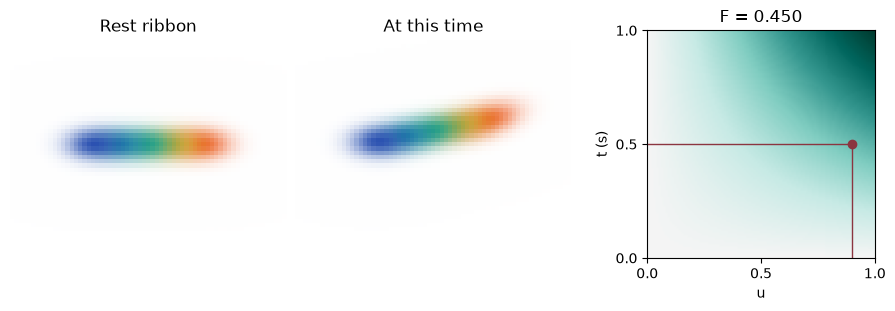

In [4]:
fig = demos.field_figure(lang="en")
plt.show()

## Turning the number into a bend

A feature of 0.45 says nothing about metres yet. We give feature value 1 a lift of 0.8 m. The vertical offset becomes $\Delta y=-0.8\cdot0.45=-0.36$ m and the new center is $(0.8,-0.36,4)$ m. One unit of feature also means −35° of rotation, so the angle is $-35\cdot0.45=-15.75$°. For a rotation around the depth axis, the four entries from lesson 12 become $q=(\cos(\theta/2),0,0,\sin(\theta/2))$. Multiplying degrees by $\pi/180$ converts them to radians for sine and cosine. Half the angle is −7.875°, about −0.1374 radians. The first quaternion entry is roughly 0.991 and the last is about −0.137.

The long scale of the resting splat is 0.27 m. Suppose a unit feature increases it by 30%. The factor is $1+0.3\cdot0.45=1.135$, giving a new scale of $0.27\cdot1.135=0.30645$ m. Color and opacity stay fixed. Together these three rules are our **decoder**. They turn a map value into changes in center, rotation and scale. Every change starts from the same rest ribbon. Repeating the calculation with time paused leaves the splat in place.

In [5]:
tip = motion.field_scene(.5)["splats"][-1]
for name in ("center", "rotation", "scales"):
    print(name, np.round(tip[name], 5))

center [ 0.8  -0.36  4.  ]
rotation [ 0.99057  0.       0.      -0.13701]
scales [0.30645 0.15    0.12   ]


## Where the model of Wu and colleagues goes further

Our map has an awkward property. Two splats with the same $x$ at different depths always receive the same bend. A query in the 4D-GS implementation has four coordinates $(x,y,z,t)$. They form six pairs: $xy$, $xz$, $yz$, $xt$, $yt$, $zt$. Each pair has a plane of learned values. Two points can fall together on the $xt$ plane yet separate on $zt$. The authors’ code interpolates the values and multiplies matching channels across planes at each resolution. If one channel reads $1,1,1,0.45,1,0.8$, the product is $0.36$. Results at different resolutions are joined into one list. [Interpolation in the authors’ implementation](https://github.com/hustvl/4DGaussians/blob/master/scene/hexplane.py)

A small neural network then predicts corrections to the canonical Gaussians. During training the rendered images are compared with observations. Four grid values and three hand-written rules make the journey of a single number visible here. The full method learns grid values, decoder parameters and the starting Gaussians from the frames. [Wu et al., 4D Gaussian Splatting, CVPR 2024](https://guanjunwu.github.io/4dgs/)

## Bending in the other direction

At 0.5 s, what changes if the upper-right node holds −1 instead of 1? Why does a different camera leave the answer for the center alone while changing the image?

<details>
<summary>Worked answer</summary>

The top row gives −0.9 and the bottom one zero. Halfway through time the feature is −0.45. The vertical offset $-0.8\cdot(-0.45)=+0.36$ m points down. The long scale is $0.27(1-0.135)=0.23355$ m. Rotation changes sign to +15.75°. Only the rest center, the time and the nodes entered those calculations. The camera first appears in the next step, when the new ellipsoid is projected onto the screen.

</details>

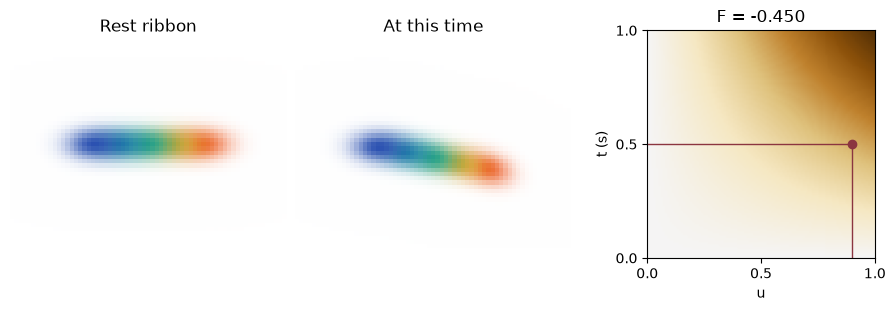

In [6]:
fig = demos.field_figure(corner=-1, lang="en")
plt.show()